<a href="https://colab.research.google.com/github/Pavan-P-N/retail-sales-analysis/blob/main/01_Retail_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Retail Sales Analysis**
-*A data analysis project using Python, Pandas, and Matplotlib.*




# Business Understanding

This project analyzes sales data from a retail store to understand how the business is performing. The dataset includes information about orders, customers, products, sales, and shipping.

The main goal is to identify useful patterns in sales data that can help the business make better decisions. By analyzing the data, we can identify the products and sub-categories generating the highest sales, the regions generating the highest sales, customer purchasing patterns, and sales trends over time.

## Business Questions

During this analysis, I will answer questions such as:

- Which regions generate the highest sales?
- Which product categories and sub-categories perform best?
- Who are the top customers by sales?
- How do sales change over time?
- Which customer segments generate the most sales?
- Which shipping methods are used most frequently?

## Goal

The goal is to use data analysis to understand the company's sales performance, identify important patterns, and provide recommendations based on the findings.

# 1) Import Libraries

In [1]:
# Data manipulation
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt

# Display plots inside the notebook
%matplotlib inline

# 2) Load Dataset

In [2]:
url = "https://raw.githubusercontent.com/Pavan-P-N/retail-sales-analysis/refs/heads/main/SampleSuperstore.csv"

df = pd.read_csv(url)

# 3) Data Inspection

In [3]:
df.head()# First five rows

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [4]:
df.shape # No of rows and columns

(9800, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [6]:
df.describe()

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [7]:
df.isnull().sum() # Finding Missing Values

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [8]:
df.duplicated().sum() # Checking for duplicate rows

np.int64(0)

## Initial Observations

* The dataset contains **9,800 records** and **18 columns**.
* There are **no duplicate rows**.
* Only the **Postal Code** column has missing values (11 records).
* The **Order Date** and **Ship Date** columns are stored as text and should be converted to datetime.
* The mean sales per record is much higher than the median, suggesting that a relatively small number of high-sales records may influence the average..


# 4) Data Cleaning

In [9]:
# Converting to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d/%m/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%d/%m/%Y")

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   object        
 2   Order Date     9800 non-null   datetime64[ns]
 3   Ship Date      9800 non-null   datetime64[ns]
 4   Ship Mode      9800 non-null   object        
 5   Customer ID    9800 non-null   object        
 6   Customer Name  9800 non-null   object        
 7   Segment        9800 non-null   object        
 8   Country        9800 non-null   object        
 9   City           9800 non-null   object        
 10  State          9800 non-null   object        
 11  Postal Code    9789 non-null   float64       
 12  Region         9800 non-null   object        
 13  Product ID     9800 non-null   object        
 14  Category       9800 non-null   object        
 15  Sub-Category   9800 n

In [11]:
df[df["Postal Code"].isna()] # Identify rows where the Postal Code column contains missing values.

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
2234,2235,CA-2018-104066,2018-12-05,2018-12-10,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03
5274,5275,CA-2016-162887,2016-11-07,2016-11-09,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,Vermont,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20
8798,8799,US-2017-150140,2017-04-06,2017-04-10,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,Vermont,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75
9146,9147,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98
9147,9148,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04
9148,9149,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29
9386,9387,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92
9387,9388,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28
9388,9389,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94
9389,9390,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04


In [12]:
# Display the unique values in categorical columns
print("Ship Modes:")
print(df["Ship Mode"].unique())

print("\nSegments:")
print(df["Segment"].unique())

print("\nRegions:")
print(df["Region"].unique())

print("\nCategories:")
print(df["Category"].unique())

print("\nSub-Categories:")
print(df["Sub-Category"].unique())

Ship Modes:
['Second Class' 'Standard Class' 'First Class' 'Same Day']

Segments:
['Consumer' 'Corporate' 'Home Office']

Regions:
['South' 'West' 'Central' 'East']

Categories:
['Furniture' 'Office Supplies' 'Technology']

Sub-Categories:
['Bookcases' 'Chairs' 'Labels' 'Tables' 'Storage' 'Furnishings' 'Art'
 'Phones' 'Binders' 'Appliances' 'Paper' 'Accessories' 'Envelopes'
 'Fasteners' 'Supplies' 'Machines' 'Copiers']


## Data Cleaning Summary

* Converted `Order Date` and `Ship Date` to datetime format.
* Checked for duplicate rows and found none.
* Found 11 missing values in `Postal Code`.
* Kept the missing postal codes because they are not needed for our analysis.
* Checked the main categorical columns and found no obvious inconsistent values.


# 5) Exploratory Data Analysis

## a) Sales by Region

In [13]:
# Calculate sales by region

region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

region_sales

,Sales
Region,
West,710219.6845
East,669518.7260
Central,492646.9132
South,389151.4590


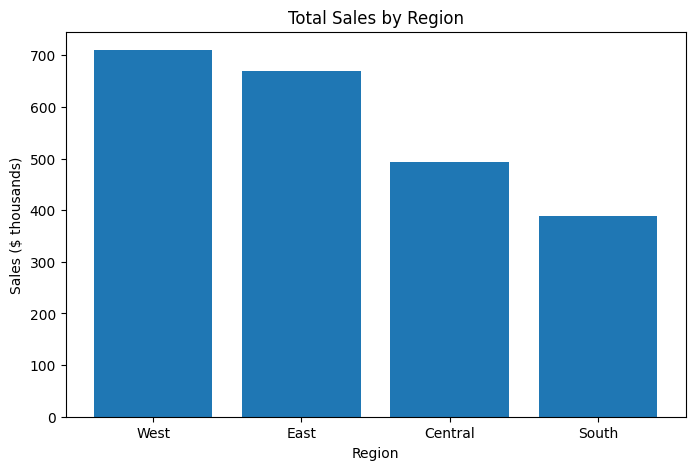

In [14]:
# Visualize total sales by region.

plt.figure(figsize=(8, 5))

plt.bar(region_sales.index, region_sales.values / 1000)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales ($ thousands)")

plt.show()

In [15]:
# Calculate the number of orders and average order value by region.

region_orders = df.groupby("Region")["Order ID"].nunique().sort_values(ascending=False)

order_sales = df.groupby(["Region", "Order ID"])["Sales"].sum()

avg_order_value = order_sales.groupby("Region").mean().sort_values(ascending=False)

print("Number of Orders:")
print(region_orders)

print("\nAverage Order Value:")
print(avg_order_value)

Number of Orders:
Region
West       1587
East       1369
Central    1156
South       810
Name: Order ID, dtype: int64

Average Order Value:
Region
East       489.056776
South      480.433900
West       447.523431
Central    426.165150
Name: Sales, dtype: float64


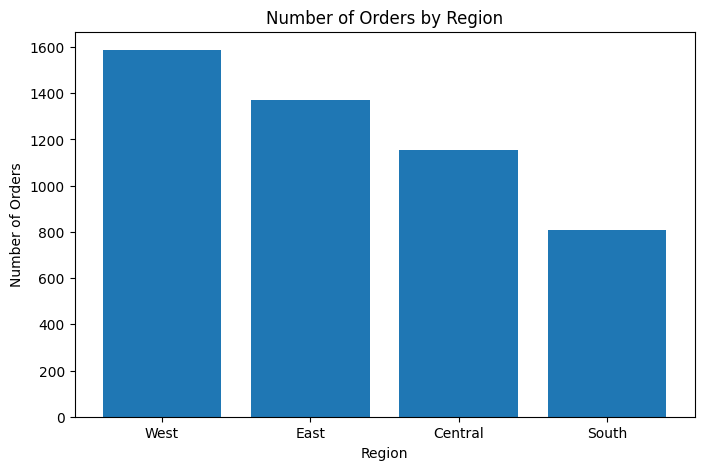

In [16]:
# Visualize Number of Orders by Region

plt.figure(figsize=(8, 5))

plt.bar(region_orders.index, region_orders.values)

plt.title("Number of Orders by Region")
plt.xlabel("Region")
plt.ylabel("Number of Orders")

plt.show()

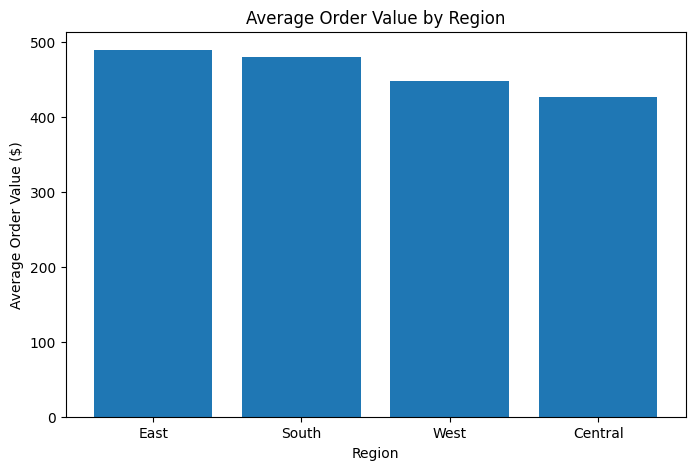

In [17]:
# Visualize Average Order Value by Region

plt.figure(figsize=(8, 5))

plt.bar(avg_order_value.index, avg_order_value.values)

plt.title("Average Order Value by Region")
plt.xlabel("Region")
plt.ylabel("Average Order Value ($)")

plt.show()

**Insight**

The West has the highest number of orders, which helps explain why it generates the most total sales. However, the East has the highest average order value despite having fewer orders than the West. The South also has relatively high-value orders but the lowest number of orders.


## b) Sales by Category


In [18]:
# Calculate sales by category

category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

category_sales

,Sales
Category,
Technology,827455.8730
Furniture,728658.5757
Office Supplies,705422.3340


In [19]:
# Calculate percentage of sales by category.

category_sales_percentage = (category_sales / category_sales.sum()) * 100

category_sales_percentage

,Sales
Category,
Technology,36.588212
Furniture,32.219621
Office Supplies,31.192167


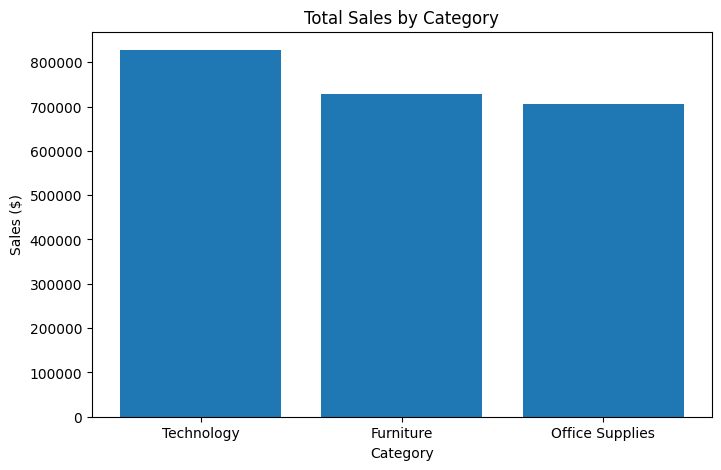

In [20]:
# Visualize Total Sales by Category

plt.figure(figsize=(8, 5))

plt.bar(category_sales.index, category_sales.values)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales ($)")

plt.show()

In [21]:
# Calculate number of orders by category.

category_orders = df.groupby("Category")["Order ID"].nunique().sort_values(ascending=False)

category_orders

,Order ID
Category,
Office Supplies,3676
Furniture,1727
Technology,1519


In [22]:
# Calculate average order value by category.

category_order_sales = df.groupby(["Category", "Order ID"])["Sales"].sum()

avg_category_sales_per_order = category_order_sales.groupby("Category").mean().sort_values(ascending=False)

avg_category_sales_per_order

,Sales
Category,
Technology,544.737244
Furniture,421.921584
Office Supplies,191.899438


**Insight**

Technology has the highest total sales even though it has the fewest orders. Its average order value is around \$545, which is much higher than Furniture (\$422) and Office Supplies (\$192). This suggests that Technology generates more revenue from higher-value orders, while Office Supplies relies on a much larger number of orders.


## c) Sales by Sub-Category

In [23]:
# Calculate Sales by Sub-Category.

subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)

subcategory_sales

,Sales
Sub-Category,
Phones,327782.4480
Chairs,322822.7310
Storage,219343.3920
Tables,202810.6280
Binders,200028.7850
Machines,189238.6310
Accessories,164186.7000
Copiers,146248.0940
Bookcases,113813.1987


In [24]:
# Calculate the top 5 sub-categories' percentage of total sales.

top_5_sales = subcategory_sales.head(5).sum()

top_5_percentage = (top_5_sales / subcategory_sales.sum()) * 100

top_5_percentage

np.float64(56.27978256804852)

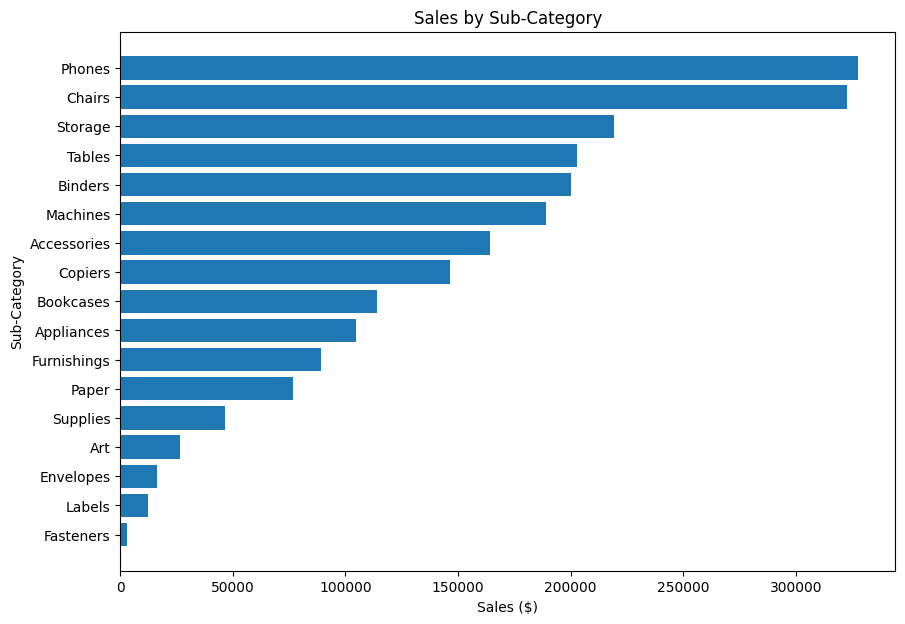

In [25]:
# Visualize Sales by Sub-Category

plt.figure(figsize=(10, 7))

plt.barh(subcategory_sales.index, subcategory_sales.values)

plt.title("Sales by Sub-Category")
plt.xlabel("Sales ($)")
plt.ylabel("Sub-Category")

plt.gca().invert_yaxis()

plt.show()

**Insight**

Phones and Chairs are the two highest-selling sub-categories, with both generating more than $320,000 in sales. There is a large difference between the highest and lowest-selling sub-categories, with Fasteners generating the lowest sales.

The top five sub-categories account for about 56% of total sales, even though there are 17 sub-categories in the dataset. This shows that a relatively small number of sub-categories contribute a large share of the company's sales.

## d) Customer Segment Analysis



In [26]:
# Calculate total sales by customer segment.

segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)

segment_sales

,Sales
Segment,
Consumer,1.148061e+06
Corporate,6.884941e+05
Home Office,4.249822e+05


In [27]:
# Calculate number of orders by customer segment.

segment_orders = df.groupby("Segment")["Order ID"].nunique().sort_values(ascending=False)

segment_orders

,Order ID
Segment,
Consumer,2537
Corporate,1491
Home Office,894


In [28]:
# Calculate average order value by customer segment.

segment_order_sales = df.groupby(["Segment", "Order ID"])["Sales"].sum()

segment_aov = segment_order_sales.groupby("Segment").mean().sort_values(ascending=False)

segment_aov

,Sales
Segment,
Home Office,475.371563
Corporate,461.766650
Consumer,452.526816


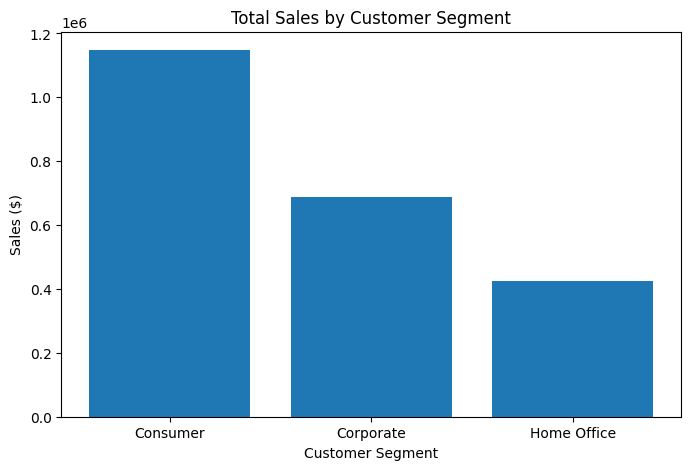

In [29]:
# Visualize Total Sales by Customer Segment

plt.figure(figsize=(8, 5))

plt.bar(segment_sales.index, segment_sales.values)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Sales ($)")

plt.show()

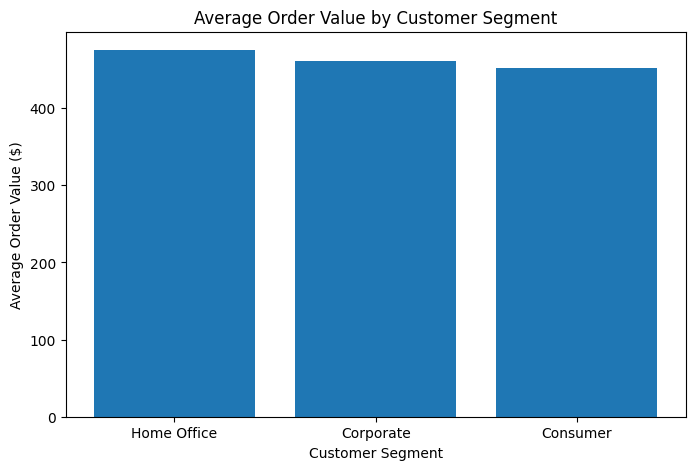

In [30]:
# Visualize Average Order Value by Customer Segment

plt.figure(figsize=(8, 5))

plt.bar(segment_aov.index, segment_aov.values)

plt.title("Average Order Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Order Value ($)")

plt.show()

**Insight**

Consumer customers generate the highest total sales and have the most orders. However, Home Office has the highest average order value despite having fewer orders. This suggests that Home Office orders tend to be higher in value, while the Consumer segment generates more sales through a larger number of orders.


## e) Sales Trends over Time

In [31]:
df["Order Date"].dt.year.unique()  # Identify the years covered by the dataset.

array([2017, 2016, 2015, 2018], dtype=int32)

In [32]:
# Calculate total sales by year.

yearly_sales = df.groupby(df["Order Date"].dt.year)["Sales"].sum()

yearly_sales

,Sales
Order Date,
2015,479856.2081
2016,459436.0054
2017,600192.5500
2018,722052.0192


In [33]:
# Calculate year-over-year sales growth.

yearly_growth = yearly_sales.pct_change() * 100

yearly_growth

,Sales
Order Date,
2015,NaN
2016,-4.255484
2017,30.636812
2018,20.303396


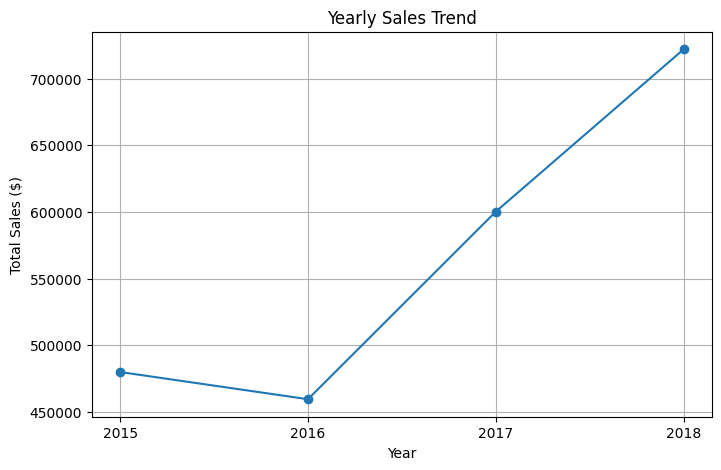

In [34]:
# Visualize Yearly Sales Trend

plt.figure(figsize=(8, 5))

plt.plot(yearly_sales.index, yearly_sales.values, marker="o")

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(yearly_sales.index)
plt.grid(True)

plt.show()

**Insight**

The store's sales generally increased between 2015 and 2018. Although sales declined slightly in 2016, they recovered strongly in 2017 and continued growing in 2018. However, the growth rate slowed from 30.64% to 20.30% in the final year.

## g) Shipping Mode Analysis

In [35]:
# Calculate number of orders by shipping mode.

shipping_orders = df.groupby("Ship Mode")["Order ID"].nunique().sort_values(ascending=False)
shipping_orders

,Order ID
Ship Mode,
Standard Class,2945
Second Class,944
First Class,772
Same Day,261


**Insight**

Standard Class is the dominant shipping method, accounting for nearly 60% of orders. Same Day shipping is used much less frequently, suggesting that most orders do not use the fastest available shipping option.

In [36]:
# Analyze shipping mode distribution across customer segments.

shipping_by_segment = (
    df.groupby(["Segment", "Ship Mode"])["Order ID"]
      .nunique()
      .unstack(fill_value=0)
)

shipping_by_segment

Ship Mode,First Class,Same Day,Second Class,Standard Class
Segment,,,,
Consumer,389,154,488,1506
Corporate,245,58,295,893
Home Office,138,49,161,546


In [37]:
# Calculate shipping mode percentages within each segment.

shipping_by_segment_percentage = (
    shipping_by_segment.div(shipping_by_segment.sum(axis=1), axis=0) * 100
).round(2)

shipping_by_segment_percentage

Ship Mode,First Class,Same Day,Second Class,Standard Class
Segment,,,,
Consumer,15.33,6.07,19.24,59.36
Corporate,16.43,3.89,19.79,59.89
Home Office,15.44,5.48,18.01,61.07


**Insight**

Shipping preferences are largely similar across all three customer segments. Standard Class is the most commonly used shipping method, accounting for approximately 59–61% of orders in each segment. This suggests that customer segment has little influence on the choice of shipping method in this dataset.

## h) Top Customers by Sales

In [38]:
# Identify the top 10 customers by sales.

customer_sales = (
    df.groupby("Customer Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

customer_sales.head(10)

,Sales
Customer Name,
Sean Miller,25043.050
Tamara Chand,19052.218
Raymond Buch,15117.339
Tom Ashbrook,14595.620
Adrian Barton,14473.571
Ken Lonsdale,14175.229
Sanjit Chand,14142.334
Hunter Lopez,12873.298
Sanjit Engle,12209.438


**Insight**

Sean Miller is the highest-value customer in terms of total sales, contributing approximately $25,043. The difference between the top two customers is significant, suggesting that sales contributions vary considerably among the highest-spending customers.

In [39]:
# Calculate the top 10 customers' share of total sales.

top_10_sales = customer_sales.head(10).sum()

top_10_percentage = (top_10_sales / df["Sales"].sum()) * 100

top_10_percentage

np.float64(6.8011791882672)

**Insight**

The top 10 customers contribute approximately 6.8% of total sales. This indicates that the business has a broad distribution of sales across its customer base, with no heavy dependence on its top 10 customers

## i) Sales by State

In [40]:
# Identify the top 10 states by sales.

state_sales = (
    df.groupby("State")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

state_sales.head(10)

,Sales
State,
California,446306.4635
New York,306361.1470
Texas,168572.5322
Washington,135206.8500
Pennsylvania,116276.6500
Florida,88436.5320
Illinois,79236.5170
Michigan,76136.0740
Ohio,75130.3500


**Insight**

California is the highest-performing state in terms of total sales, generating approximately $446,306, followed by New York with $306,361. These two states stand out as the largest contributors to the store's sales

In [41]:
# Calculate the top 2 states' share of total sales.

top_2_state_sales = state_sales.head(2).sum()

top_2_state_percentage = (
    top_2_state_sales / df["Sales"].sum()
) * 100

top_2_state_percentage

np.float64(33.281245578566555)

**Insight**

California and New York are the two highest-performing states, together contributing approximately 33.28% of total sales. This indicates that a significant portion of the store's sales comes from these two states.

## j) Sales by City

In [42]:
# Identify the top 10 cities by sales.

city_sales = (
    df.groupby("City")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

city_sales.head(10)

,Sales
City,
New York City,252462.5470
Los Angeles,173420.1810
Seattle,116106.3220
San Francisco,109041.1200
Philadelphia,108841.7490
Houston,63956.1428
Chicago,47820.1330
San Diego,47521.0290
Jacksonville,44713.1830


**Insight**

New York City is the highest-performing city, generating approximately \$252,463 in sales, followed by Los Angeles with $173,420. Sales are concentrated among a few leading cities, particularly the top two.

In [43]:
# Calculate the top 10 cities' share of total sales.

top_10_city_sales = city_sales.head(10).sum()

top_10_city_percentage = (
    top_10_city_sales / df["Sales"].sum()
) * 100

top_10_city_percentage

np.float64(44.49758936038904)

**Insight**

The top 10 cities contribute approximately 44.5% of total sales. New York City and Los Angeles are the two largest contributors, indicating that a substantial share of sales comes from a relatively small group of cities.

# 6) Business Insights

1. **Regional performance**: The West region generates the highest sales (31.4%), followed by the East region (29.6%).

2. **Category performance**: Technology generates the highest sales (36.6%), although sales are fairly evenly distributed across the three categories.

3. **Sub-category performance**: Phones and Chairs are the leading sub-categories. The top five sub-categories contribute approximately 56.3% of total sales.

4. **Customer segments**: Consumer customers generate the highest total sales, while Home Office customers have the highest average order value.

5. **Sales trends**: Sales increased from approximately \$479,856 in 2015 to $722,052 in 2018, despite a small decline in 2016.

6. **Shipping preferences**: Standard Class accounts for approximately 59–61% of orders across all three customer segments.

7. **Customer contribution**: The top 10 customers contribute only 6.8% of total sales, suggesting sales are spread across a broad customer base.

8. **Geographical performance**: California and New York together contribute 33.3% of total sales. The top 10 cities contribute approximately 44.5%

# 7) Business Recommendations

1. **Focus on high-performing regions**: Continue building on the strong sales performance of the West and East regions while exploring opportunities to increase sales in the Central and South regions.

2. **Promote high-sales sub-categories**: Give attention to Phones, Chairs, and Storage, which generate the highest sales revenue. Further analysis could help determine whether their performance comes from higher prices or greater sales volume.

3. **Understand customer segments**: Consumer customers generate the highest total sales. The business could explore ways to retain these customers while identifying opportunities to increase sales among Corporate and Home Office customers.

4. **Investigate geographical opportunities**: California and New York generate a substantial share of sales. The business could study what contributes to their strong performance and explore similar opportunities in other states.

5. **Monitor sales growth**: Sales have increased since 2016, but the growth rate slowed in 2018. The business should monitor future sales trends to understand whether this slowdown continues.

6. **Monitor shipping performance**: Standard Class is the most frequently used shipping method. The business could monitor delivery performance and customer feedback to evaluate whether this service meets expectations

# 8) Conclusion

This project analyzed retail sales data to understand business performance across different regions, product categories, customer segments, and shipping methods. The analysis identified the West region, Technology category, and Consumer segment as major contributors to total sales. It also revealed that sales increased between 2015 and 2018, with some variation in yearly growth.

The findings provide a better understanding of sales patterns and highlight areas where the business could explore further opportunities. Overall, this project demonstrates how data analysis can turn raw sales data into useful business insights.